# 서포트 벡터 머신 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week05/svm/lab/svm.ipynb)

가장 넓은 길을 내는 분류기. 마진과 서포트 벡터를 확인하고, 실제 데이터와 휘어진 데이터에서 C · γ 를 고른다.

- **파트 1**: 슬라이드의 점 20개: 마진 3.18, 서포트 벡터 3개
- **파트 2**: 지폐 1,372장 진위 판별: 선형 vs RBF
- **파트 3**: 원 · 반달 데이터에서 C 와 γ 를 교차 검증으로

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

## 슬라이드의 예시 데이터

In [ ]:
# Same example as the slides: 10 red (+1) and 10 blue (-1) points
X = np.array([[1.5, 6.0], [2.0, 7.5], [2.5, 5.5], [3.0, 7.0], [1.0, 8.0], [3.5, 6.0], [2.0, 4.5], [3.0, 8.5], [1.2, 5.2], [4.0, 7.8],   # red
              [6.0, 2.5], [7.0, 4.0], [5.5, 1.5], [8.0, 2.0], [6.5, 3.5], [7.5, 1.0], [5.0, 3.0], [8.5, 3.5], [6.0, 0.8], [7.8, 5.0]])  # blue
y = np.array([1] * 10 + [-1] * 10)

def plot_svm(model, X, y, ax=None, title=""):
    ax = ax or plt.gca()
    gx, gy = np.meshgrid(np.linspace(0, 10, 200), np.linspace(0, 10, 200))
    Z = model.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contour(gx, gy, Z, levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm_r")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=200, facecolors="none", edgecolors="gold", linewidths=2)
    ax.set_aspect("equal"); ax.set_title(title)

## 파트 1. 마진과 서포트 벡터

`C` 를 아주 크게 하면 하드 마진(길 안에 점 없음). 마진 $= 2/\lVert\mathbf{w}\rVert$.

In [ ]:
model = SVC(kernel="linear", C=1e6).fit(X, y)
w, b = model.coef_[0], model.intercept_[0]
margin = None  # TODO: width of the street
print("w =", w.round(3), " b =", round(b, 3), " margin =", round(margin, 2))
print("support vectors:", model.support_vectors_.tolist())

X_moved = X.copy()
X_moved[4] = [0.3, 9.5]                                   # move a far-away red point
model2 = SVC(kernel="linear", C=1e6).fit(X_moved, y)
print("w after moving a far point:", model2.coef_[0].round(3))
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
plot_svm(model, X, y, axs[0], "original"); plot_svm(model2, X_moved, y, axs[1], "far point moved"); plt.show()

**예상 결과**

```
w = [-0.445  0.444]  b = -0.109  margin = 3.18
support vectors: [[5.0, 3.0], [3.5, 6.0], [2.0, 4.5]]
w after moving a far point: [-0.445  0.444]
```

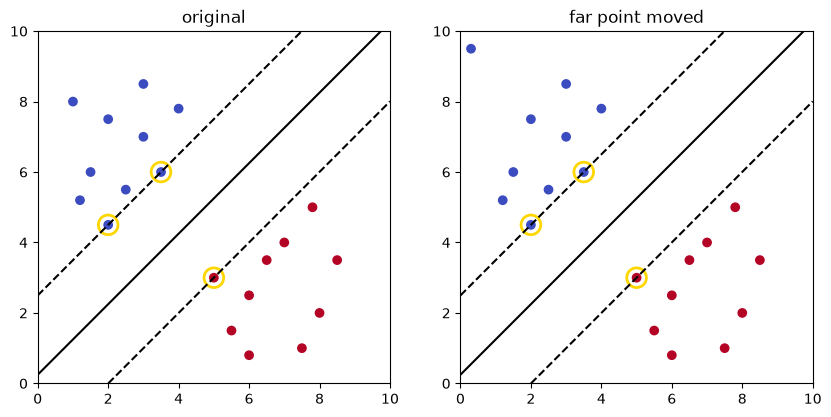

In [ ]:
# Soft margin: add one blue outlier inside the red group
X_out = np.r_[X, [[3.0, 5.2]]]; y_out = np.r_[y, [-1]]
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, C in zip(axs, [100, 1, 0.05]):
    m = SVC(kernel="linear", C=C).fit(X_out, y_out)
    n_sv = None  # TODO: number of support vectors
    plot_svm(m, X_out, y_out, ax, f"C={C}: margin {2 / np.linalg.norm(m.coef_[0]):.2f}, {n_sv} SVs")
plt.show()

**예상 결과**

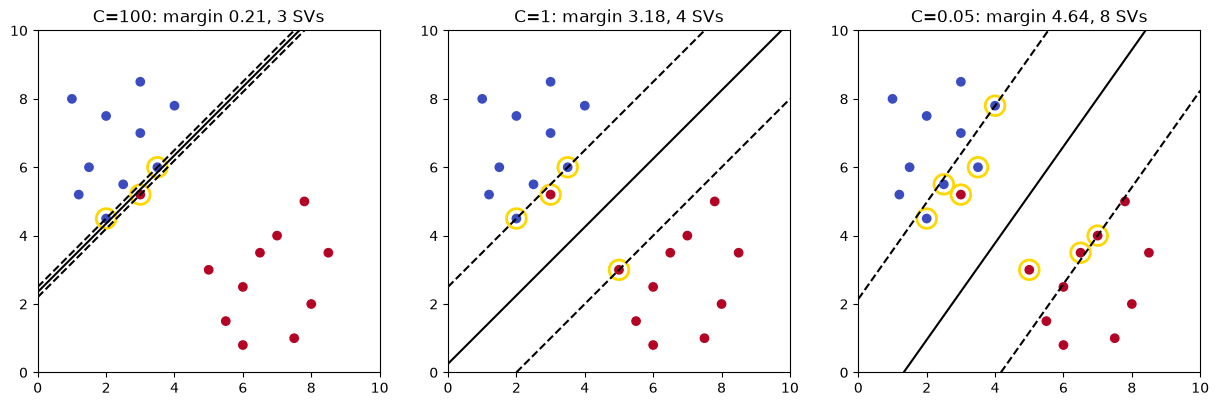

## 파트 2. 실제 데이터: 지폐 진위 판별

지폐 사진을 웨이블릿 변환해서 뽑은 특징 4개(분산, 왜도, 첨도, 엔트로피) 로 진짜(0) / 위조(1) 를 가린다. 처음 실행하면 내려받는다.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/banknote.csv"):
    import urllib.request; urllib.request.urlretrieve(url, "data/banknote.csv")
df = pd.read_csv("data/banknote.csv", header=None, names=["variance", "skewness", "curtosis", "entropy", "fake"])
Xb, yb = df.iloc[:, :4].to_numpy(), df["fake"].to_numpy()
print(df.shape, "fake rate", round(yb.mean(), 3))
for kernel in ["linear", "rbf"]:
    pipe = make_pipeline(StandardScaler(), SVC(kernel=kernel))
    acc = None  # TODO: 5-fold CV accuracy
    print(f"{kernel:6s}: CV accuracy {acc:.4f}")

**예상 결과**

```
(1372, 5) fake rate 0.445
linear: CV accuracy 0.9861
rbf   : CV accuracy 1.0000
```

## 파트 3. C 와 γ 고르기

반달 데이터. `GridSearchCV` 는 모든 (C, γ) 조합을 교차 검증해서 가장 좋은 것을 고른다.

In [ ]:
from sklearn.datasets import make_moons
Xm, ym = make_moons(300, noise=0.25, random_state=0)
grid = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.1, 1, 10, 100]}, cv=5)
grid.fit(Xm, ym)
print("best:", grid.best_params_, " CV accuracy", round(grid.best_score_, 3))
table = pd.DataFrame(grid.cv_results_["mean_test_score"].reshape(4, 4), index=[0.1, 1, 10, 100], columns=[0.1, 1, 10, 100])
print("rows = C, columns = gamma"); print(table.round(3))

**예상 결과**

```
best: {'C': 10, 'gamma': 1}  CV accuracy 0.963
rows = C, columns = gamma
       0.1    1.0    10.0   100.0
0.1    0.810  0.907  0.953  0.880
1.0    0.837  0.957  0.960  0.927
10.0   0.870  0.963  0.953  0.917
100.0  0.943  0.950  0.923  0.917
```

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
gx, gy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 250))
for ax, g in zip(axs, [0.1, grid.best_params_["gamma"], 100]):
    m = SVC(kernel="rbf", C=grid.best_params_["C"], gamma=g).fit(Xm, ym)
    Z = m.decision_function(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, Z > 0, alpha=0.2); ax.contour(gx, gy, Z, levels=[0], colors="k")
    ax.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=10); ax.set_title(f"gamma={g}")
plt.show()

**예상 결과**

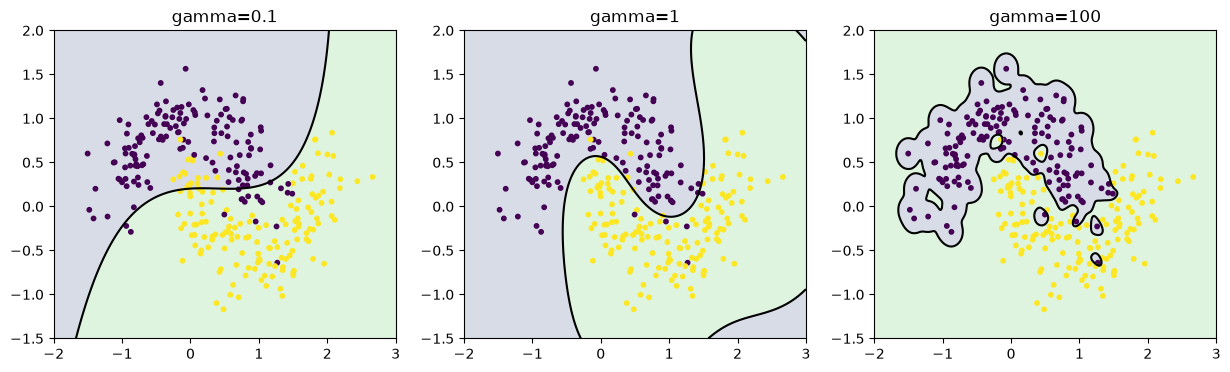

**확인 질문**
1. 파트 1 에서 서포트 벡터 하나를 옮기면 w 가 바뀌는가? 직접 해 보자.
2. 파트 1 의 소프트 마진에서 C 를 줄일수록 서포트 벡터 수는 어떻게 되나? 왜 그럴까?
3. 파트 2 에서 RBF 가 선형보다 조금 높다. 그래도 선형을 고를 이유가 있다면 무엇일까? (서포트 벡터 수, 예측 속도, 설명하기 쉬움)
4. 파트 3 의 표에서 C 와 γ 가 둘 다 클 때 정확도가 떨어지는 이유는?

데이터 출처: Banknote Authentication, UCI Machine Learning Repository (Volker Lohweg, 2012).